### 🤖 What are Multi-Agent RAG Systems?
A Multi-Agent RAG System splits the RAG pipeline into multiple specialized agents — each responsible for a specific role — and enables them to collaborate on a single query or task.

#### 1. 📋 Multi-Agent Network RAG System with LangGraph
Project Overview

A beginner-friendly Retrieval-Augmented Generation (RAG) system that uses a multi-agent architecture to intelligently answer questions from your documents. Built with LangGraph v0.3 for workflow orchestration and OpenAI for language understanding.

What It Does

Transforms your documents (PDFs, text files) into a searchable knowledge base that can answer questions intelligently using AI. Simply upload documents and ask questions in natural language - the system finds relevant information and generates comprehensive answers.
Key Features

- 📚 Multi-Format Support: Handles PDF and text documents
- 🤖 3-Agent Architecture: Specialized agents for document processing, retrieval, and answer generation
- 🔍 Smart Search: Vector-based semantic search finds relevant information
- 💬 Natural Language Q&A: Ask questions in plain English


In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain_groq import ChatGroq
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [2]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002250D3FFA10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002250D5A0830>, model_name='openai/gpt-oss-120b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [5]:
!uv pip install langchain-tavily

Using Python 3.13.15 environment at: D:\Mission Project\AgenticAI\agc
Resolved 48 packages in 1.68s
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 1 package in 44ms
 + langchain-tavily==0.2.18


In [6]:

from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS

from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter


In [7]:
tavily_tool=TavilySearch(max_results=5)

In [8]:
embedding= HuggingFaceEmbeddings(
    model_name ="sentence-transformers/all-MiniLM-L6-v2"
)
embedding = embedding

d:\Mission Project\AgenticAI\agc\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3483.22it/s]


In [14]:
## Generic function to create a retrieval tool
from langchain_core.tools import Tool

def make_retriever_tool_from_text(file,name,desc):
    docs = TextLoader(file,encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, embedding)
    retriever = vs.as_retriever()

    def tool_func(query:str)-> str:
        print(f" Using tool: {name}")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results)

    return Tool(name=name, description=desc,func=tool_func)

internal_tool_1 = make_retriever_tool_from_text("research_notes.txt",
                                                "InernalResearchNotes",
                                                "Search internal research notes for experimental results" )

internal_tool_1

Tool(name='InernalResearchNotes', description='Search internal research notes for experimental results', func=<function make_retriever_tool_from_text.<locals>.tool_func at 0x00000225552DB600>)

In [21]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.graph import MessagesState, END
from langgraph.types import Command

def get_next_node(last_message: BaseMessage, goto: str):
    if "FINAL ANSWER" in last_message.content:
        # Any agent decided the work is done
        return END
    return goto

In [16]:
def make_system_prompt(suffix: str) -> str:
    return (
        "You are a helpful AI Assistant, collaborating with other assistants."
        "Use the provided tools to progress towards answering the question."
        "If you a unable to fully answer, that's OK, another assistant with differernt tools"
        "will help where you left off. Execute what you can make progress."
        "If you or any of the other assistants have the final answer or deliverable,"
        "prefix your response with FINAL ANSWER so the team know to stop."
        f"\n{suffix}"
    )

C:\Users\aadit\AppData\Local\Temp\ipykernel_22596\4018498606.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


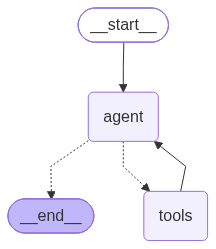

In [17]:
## Research agent and node
research_agent = create_react_agent(
    llm,
    tools=[internal_tool_1, tavily_tool],
    prompt = make_system_prompt("You can only do research. Use the tool that you are binded with, you can use both of them" \
    "You are working with a content writer colleague.")
)

research_agent

In [22]:
## Research Node
from typing import Literal

def research_node(state: MessagesState) -> Command[Literal["blog_generator",END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # wrap in a human message, as not all providers allow
    # AI message at the last position of the input message list
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content, name = "researcher"
    )
    return Command(
        update={
            # SHare internal message history of research agent with other agents
            "messages": result["messages"],
        },
        goto=goto,
    )

In [23]:
## Blog write agent
blog_agent = create_react_agent(
    llm,
    tools=[],
    prompt=make_system_prompt(
        "You can only write a detailed blog. You are working with a researcher collegue"
    )
)

def blog_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = blog_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")
    # wrap in a human message, as not all providers allow
    # AI message at the last position of the input messages list
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content, name="blog_generator"
    )
    return Command(
        update={
            # share internal message history of chat agent with other agents
            "messages": result["messages",]
        },
        goto=goto
    )

C:\Users\aadit\AppData\Local\Temp\ipykernel_22596\3777930312.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent = create_react_agent(


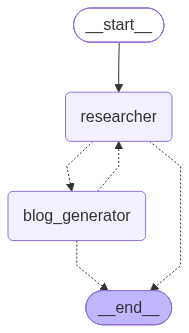

In [25]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("blog_generator",blog_node)

workflow.add_edge(START, "researcher")
graph = workflow.compile()
graph

In [27]:
response = graph.invoke({"messages": "Write a detailed blog on transformer variants in production deployments"})

In [28]:
response["messages"][-1].content

'**FINAL ANSWER**\n\n# Transformer Variants in Production Deployments  \n*Your go‑to guide for selecting, optimizing, and serving the right transformer model at scale*  \n\n---\n\n## Table of Contents\n1. [Why Transformers Still Dominate Production AI](#why-transformers-still-dominate-production-ai)  \n2. [The Landscape of Transformer Variants](#the-landscape-of-transformer-variants)  \n   - Encoder‑only (BERT family)  \n   - Decoder‑only (GPT family)  \n   - Encoder‑decoder (T5, BART)  \n   - Compact / distilled models (DistilBERT, TinyBERT, MobileBERT, ALBERT, MiniLM)  \n   - Vision‑oriented variants (ViT, EfficientFormer, MobileViT)  \n   - Emerging sparse / mixture‑of‑experts models (Phi‑3‑Mini, Mamba‑3B)  \n3. [Choosing the Right Variant for Your Use‑Case](#choosing-the-right-variant-for-your-use-case)  \n4. [Production‑Ready Optimization Pipeline](#production‑ready-optimization-pipeline)  \n5. [Inference Engines & Runtime Choices](#inference-engines--runtime-choices)  \n6. [Hardw